# 12 · External mass transfer and packed-bed reactors

Before a reactant can diffuse into a pellet it must cross the boundary layer around it, and at high
temperature or on very active catalysts that film is the bottleneck: the reaction becomes "mass-transfer
limited", indifferent to temperature and to the catalyst itself. This notebook estimates mass-transfer
coefficients from correlations, combines external and internal resistances into an overall effectiveness
factor, tests for external limitations with the Mears criterion, and designs a mass-transfer-limited bed.

**What you will learn**
- estimate mass-transfer coefficients from correlations
- combine film, pore and surface resistances
- apply the Mears criterion
- design a mass-transfer-limited bed and recognise the regime

**Before you start:** notebook 11  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import catalysis, kinetics
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Mass-transfer coefficients from the Frossling correlation

In [2]:
D_AB, nu, d_p = 1.5e-5, 1.6e-5, 3e-3                              # gas at ~400 K: diffusivity, kinematic viscosity, pellet diameter
Sc = nu / D_AB
print(f"Schmidt number {Sc:.2f}")
rows = []
for U in (0.05, 0.2, 0.5, 1.0, 2.0):
    Re = U * d_p / nu
    Sh = catalysis.sherwood_frossling(Re, Sc)
    rows.append((U, Re, Sh, Sh * D_AB / d_p))
print(pd.DataFrame(rows, columns=["U (m/s)", "Re", "Sh", "k_c (m/s)"]).round(3).to_string(index=False))

Schmidt number 1.07
 U (m/s)      Re     Sh  k_c (m/s)
    0.05   9.375  3.877      0.019
    0.20  37.500  5.754      0.029
    0.50  93.750  7.936      0.040
    1.00 187.500 10.394      0.052
    2.00 375.000 13.872      0.069


The mass-transfer coefficient grows with the square root of velocity (Frossling: Sh = 2 + 0.6 Re$^{1/2}$Sc$^{1/3}$)
and never falls below the stagnant limit Sh = 2. Doubling the gas velocity raises $k_c$ by 40 % - the reason
a mass-transfer-limited reactor responds to flow rate and not to temperature.

## Combining the resistances

In [3]:
k_c, a_c = 0.05, 1200.0                                             # m/s, m2 per m3 of bed (3 mm spheres, phi = 0.4)
for k_int, label in ((0.1, "slow kinetics"), (10.0, "moderate"), (1000.0, "very fast")):
    for eta in (1.0, 0.3):
        Omega = catalysis.overall_effectiveness(eta, k_int, k_c, a_c)
        print(f"{label:<14} k = {k_int:7.1f} 1/s, eta = {eta}: overall effectiveness Omega = {Omega:.4f}; observed rate = {Omega * k_int:8.3f} x C_bulk")

slow kinetics  k =     0.1 1/s, eta = 1.0: overall effectiveness Omega = 0.9983; observed rate =    0.100 x C_bulk
slow kinetics  k =     0.1 1/s, eta = 0.3: overall effectiveness Omega = 0.2999; observed rate =    0.030 x C_bulk
moderate       k =    10.0 1/s, eta = 1.0: overall effectiveness Omega = 0.8571; observed rate =    8.571 x C_bulk
moderate       k =    10.0 1/s, eta = 0.3: overall effectiveness Omega = 0.2857; observed rate =    2.857 x C_bulk
very fast      k =  1000.0 1/s, eta = 1.0: overall effectiveness Omega = 0.0566; observed rate =   56.604 x C_bulk
very fast      k =  1000.0 1/s, eta = 0.3: overall effectiveness Omega = 0.0500; observed rate =   50.000 x C_bulk


The observed rate is $\Omega k C_b$ with $\Omega = \eta/(1 + \eta k/(k_c a_c))$: for slow kinetics the film does
not matter and $\Omega = \eta$; for very fast kinetics the observed rate saturates at $k_c a_c C_b$ regardless
of $k$ or $\eta$. Three resistances in series - film, pore, surface - and the largest one rules.

## The Mears criterion

In [4]:
for r_obs in (1e-3, 1e-2, 1e-1, 1.0):
    M = catalysis.mears_criterion(r_obs, rho_b=900.0, R=1.5e-3, order=1, k_c=0.05, C_b=20.0)
    print(f"observed rate {r_obs:.0e} mol/(kg s): Mears number {M:.3f} -> " + ("external mass transfer negligible" if M < 0.15 else "external mass transfer matters"))

observed rate 1e-03 mol/(kg s): Mears number 0.001 -> external mass transfer negligible
observed rate 1e-02 mol/(kg s): Mears number 0.013 -> external mass transfer negligible
observed rate 1e-01 mol/(kg s): Mears number 0.135 -> external mass transfer negligible
observed rate 1e+00 mol/(kg s): Mears number 1.350 -> external mass transfer matters


Mears' test, like Weisz-Prater's for internal diffusion, uses only observables: if $-r_{obs}\rho_b R n/(k_c C_b) < 0.15$,
the film drop in concentration is below 5 % and the measurement reflects the catalyst. Both criteria belong
in every laboratory report on a solid catalyst.

## A mass-transfer-limited packed bed

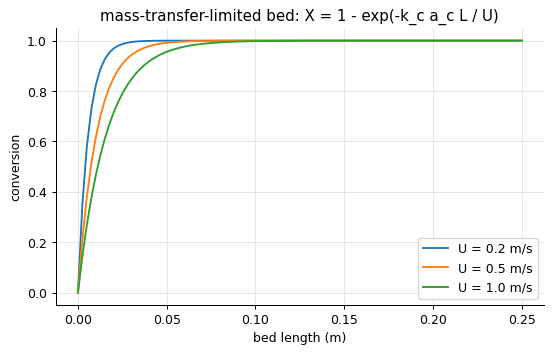

at U = 0.5 m/s the bed length for 99 % conversion is 0.05 m; doubling the velocity needs 0.07 m


In [5]:
L = np.linspace(0, 0.25, 100)
fig, ax = plt.subplots()
for U in (0.2, 0.5, 1.0):
    Re = U * d_p / nu
    k_c_ = catalysis.sherwood_frossling(Re, Sc) * D_AB / d_p
    ax.plot(L, catalysis.external_limited_conversion(k_c_, a_c, U, L), label=f"U = {U} m/s")
ax.set(xlabel="bed length (m)", ylabel="conversion", title="mass-transfer-limited bed: X = 1 - exp(-k_c a_c L / U)"); ax.legend(); plt.show()
U = 0.5
k_c_ = catalysis.sherwood_frossling(U * d_p / nu, Sc) * D_AB / d_p
L99 = -np.log(0.01) * U / (k_c_ * a_c)
print(f"at U = 0.5 m/s the bed length for 99 % conversion is {L99:.2f} m; doubling the velocity needs {(-np.log(0.01) * 1.0 / (catalysis.sherwood_frossling(1.0 * d_p / nu, Sc) * D_AB / d_p * a_c)):.2f} m")

When the film controls, the bed behaves like an absorber: conversion depends on $k_c a_c L/U$, and since
$k_c \propto U^{1/2}$ the required length grows as $U^{1/2}$. Catalytic converters and combustion catalysts run
here - and the apparent activation energy of such a reactor is a few kJ/mol, the temperature dependence of
diffusion, which is how one recognises the regime in the plant.

## Inside the algorithm: resistances in series

In [6]:
eta_, k_, kc_, ac_ = 0.3, 10.0, 0.05, 1200.0
print("by hand: Omega =", 1 / (1 / eta_ + k_ / (kc_ * ac_)), "; library:", catalysis.overall_effectiveness(eta_, k_, kc_, ac_))

by hand: Omega = 0.2857142857142857 ; library: 0.2857142857142857


## Exercises
1. A catalytic converter oxidises CO at 800 K on a monolith (k_c a_c = 60 1/s at U = 5 m/s). Find the monolith length for 99 % conversion, and the apparent activation energy you would measure if the film controls (D_AB ~ T^1.75).
2. For the packed bed of the notebook, compute the pressure drop (Ergun, notebook 04) for the bed lengths needed at U = 0.2, 0.5 and 1.0 m/s. Which velocity minimises the compressor work per unit conversion?
3. **Implement it yourself:** write the Frossling correlation and compute k_c for pellets of 1, 3 and 10 mm at U = 0.5 m/s; explain why small pellets have larger k_c but also a larger pressure drop.